<a href="https://colab.research.google.com/github/wahidshaikh0787-byte/GitHub-practical-test./blob/main/House_Price_EDA_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
numeric_cols = df.select_dtypes(include=['number']).columns.tolist()

categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

ordinal_cols = ['OverallQual', 'ExterQual', 'KitchenQual']

print("Numerical columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))
print("Ordinal columns:", ordinal_cols)

Numerical columns: 38
Categorical columns: 43
Ordinal columns: ['OverallQual', 'ExterQual', 'KitchenQual']


In [ ]:
from pandas.api.types import CategoricalDtype

quality_order = ['Po', 'Fa', 'TA', 'Gd', 'Ex']

for col in ['ExterQual', 'KitchenQual']:
    df[col] = df[col].astype(
        CategoricalDtype(categories=quality_order, ordered=True)
    )

print("ExterQual order:", df['ExterQual'].cat.categories.tolist())
print("KitchenQual order:", df['KitchenQual'].cat.categories.tolist())

ExterQual order: ['Po', 'Fa', 'TA', 'Gd', 'Ex']
KitchenQual order: ['Po', 'Fa', 'TA', 'Gd', 'Ex']


In [ ]:
columns = ['SalePrice', 'GrLivArea', 'LotArea']

for col in columns:
    print("\nStatistics for:", col)
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])
    print("Standard Deviation:", df[col].std())
    print("Variance:", df[col].var())
    print("Range:", df[col].max() - df[col].min())
    print("IQR:", df[col].quantile(0.75) - df[col].quantile(0.25))
    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurt())


Statistics for: SalePrice
Mean: 180921.19589041095
Median: 163000.0
Mode: 140000
Standard Deviation: 79442.50288288663
Variance: 6311111264.297451
Range: 720100
IQR: 84025.0
Skewness: 1.8828757597682129
Kurtosis: 6.536281860064529

Statistics for: GrLivArea
Mean: 1515.463698630137
Median: 1464.0
Mode: 864
Standard Deviation: 525.4803834232027
Variance: 276129.63336259616
Range: 5308
IQR: 647.25
Skewness: 1.3665603560164552
Kurtosis: 4.895120580693174

Statistics for: LotArea
Mean: 10516.828082191782
Median: 9478.5
Mode: 7200
Standard Deviation: 9981.264932379147
Variance: 99625649.6503417
Range: 213945
IQR: 4048.0
Skewness: 12.207687851233496
Kurtosis: 203.24327101886033


Original SalePrice skewness: 1.8828757597682129
Log SalePrice skewness: 0.12134661989685333


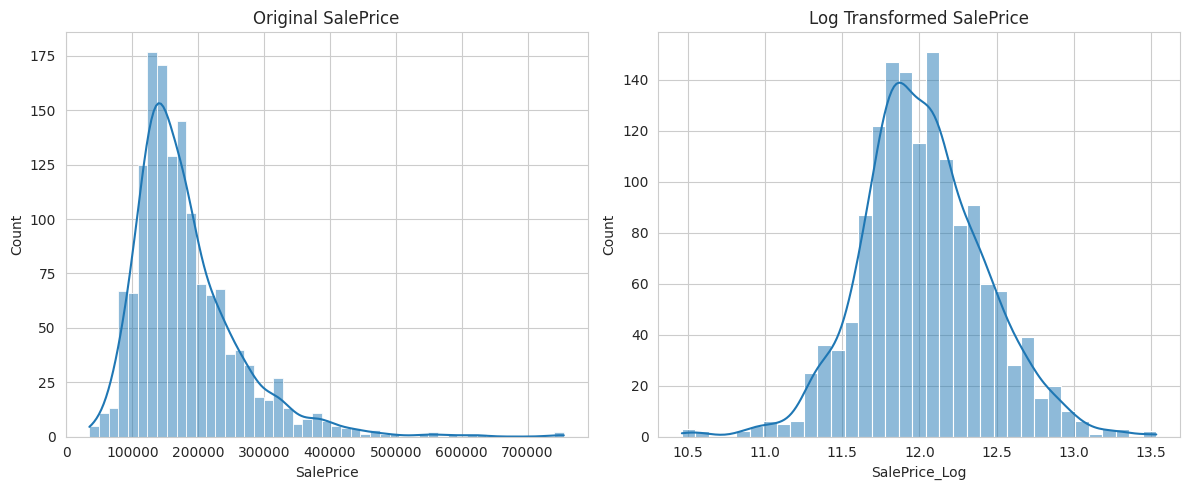

In [ ]:
import numpy as np

df['SalePrice_Log'] = np.log1p(df['SalePrice'])

print("Original SalePrice skewness:", df['SalePrice'].skew())
print("Log SalePrice skewness:", df['SalePrice_Log'].skew())

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['SalePrice'], kde=True)
plt.title('Original SalePrice')

plt.subplot(1, 2, 2)
sns.histplot(df['SalePrice_Log'], kde=True)
plt.title('Log Transformed SalePrice')

plt.tight_layout()
plt.show()

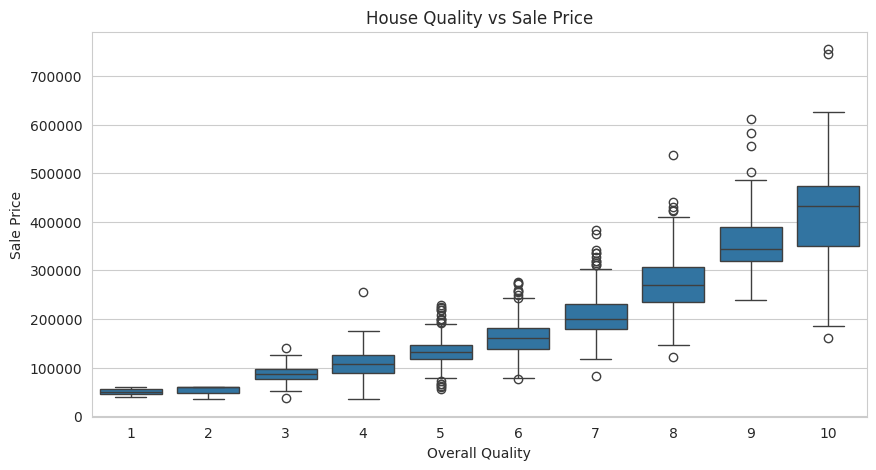

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(x='OverallQual', y='SalePrice', data=df)

plt.title('House Quality vs Sale Price')
plt.xlabel('Overall Quality')
plt.ylabel('Sale Price')

plt.show()

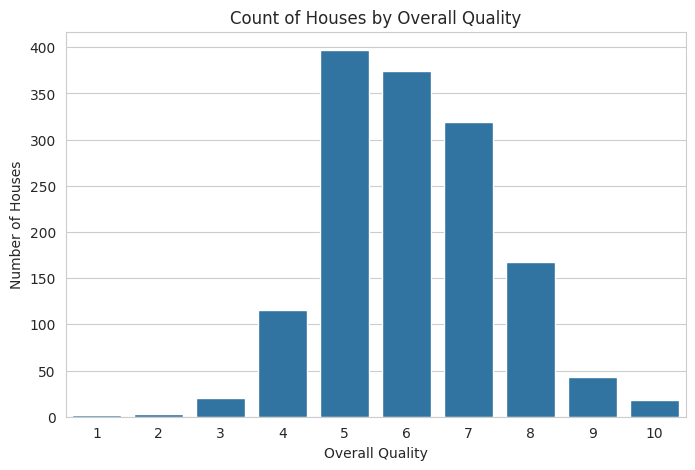

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(x='OverallQual', data=df)

plt.title('Count of Houses by Overall Quality')
plt.xlabel('Overall Quality')
plt.ylabel('Number of Houses')

plt.show()

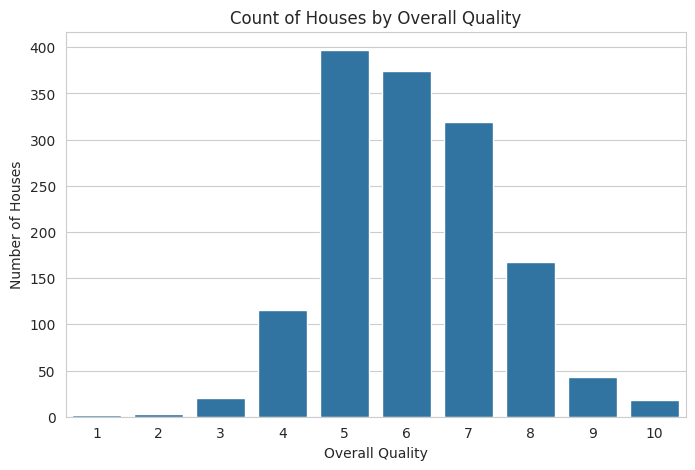

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(x='OverallQual', data=df)

plt.title('Count of Houses by Overall Quality')
plt.xlabel('Overall Quality')
plt.ylabel('Number of Houses')

plt.show()

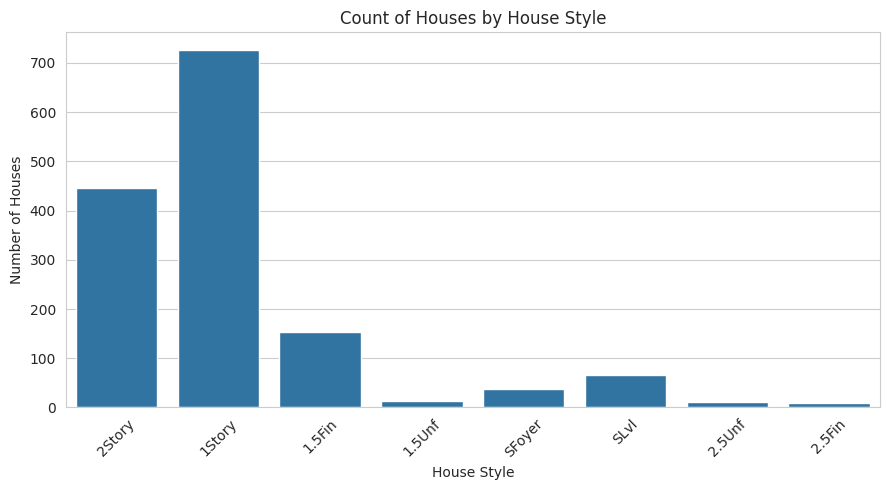

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(x='HouseStyle', data=df)

plt.title('Count of Houses by House Style')
plt.xlabel('House Style')
plt.ylabel('Number of Houses')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
cov_matrix = df.select_dtypes(include='number').cov()

corr_matrix = df.select_dtypes(include='number').corr()

top_features = corr_matrix['SalePrice'].abs().sort_values(ascending=False).index[1:4]

print("Top 3 features correlated with SalePrice:\n")

for col in top_features:
    print("Feature:", col)
    print("Correlation:", corr_matrix.loc[col, 'SalePrice'])
    print("Covariance:", cov_matrix.loc[col, 'SalePrice'])
    print("-------------------------")

Top 3 features correlated with SalePrice:

Feature: SalePrice_Log
Correlation: 0.9483743770902764
Covariance: 30095.001246838525
-------------------------
Feature: OverallQual
Correlation: 0.7909816005838053
Covariance: 86904.12583679946
-------------------------
Feature: GrLivArea
Correlation: 0.7086244776126515
Covariance: 29581866.743236575
-------------------------


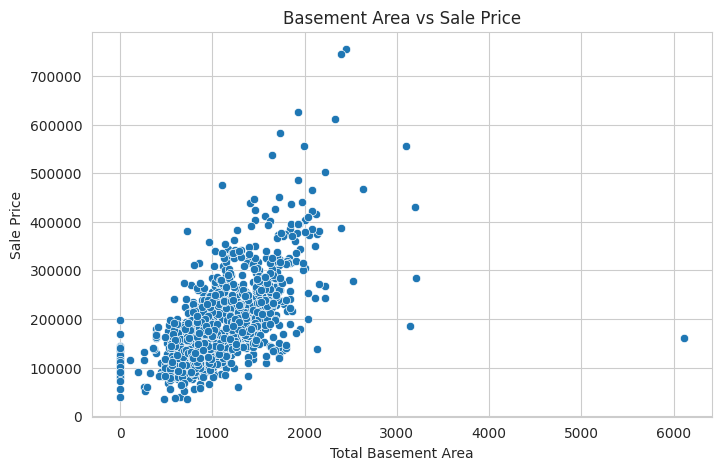

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(x='TotalBsmtSF', y='SalePrice', data=df)

plt.title('Basement Area vs Sale Price')
plt.xlabel('Total Basement Area')
plt.ylabel('Sale Price')

plt.show()

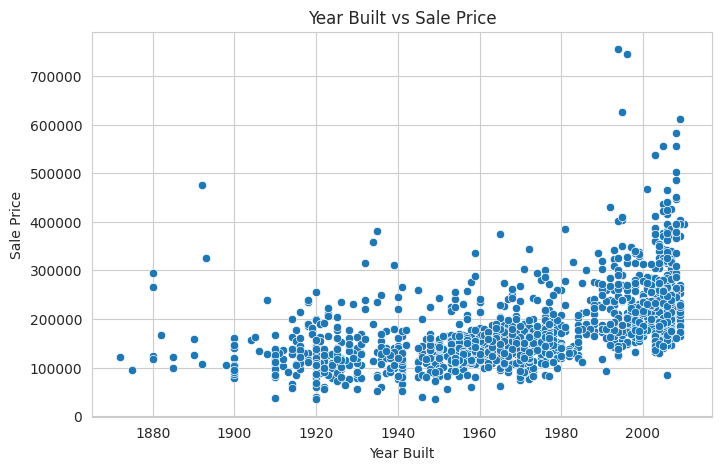

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(x='YearBuilt', y='SalePrice', data=df)

plt.title('Year Built vs Sale Price')
plt.xlabel('Year Built')
plt.ylabel('Sale Price')

plt.show()

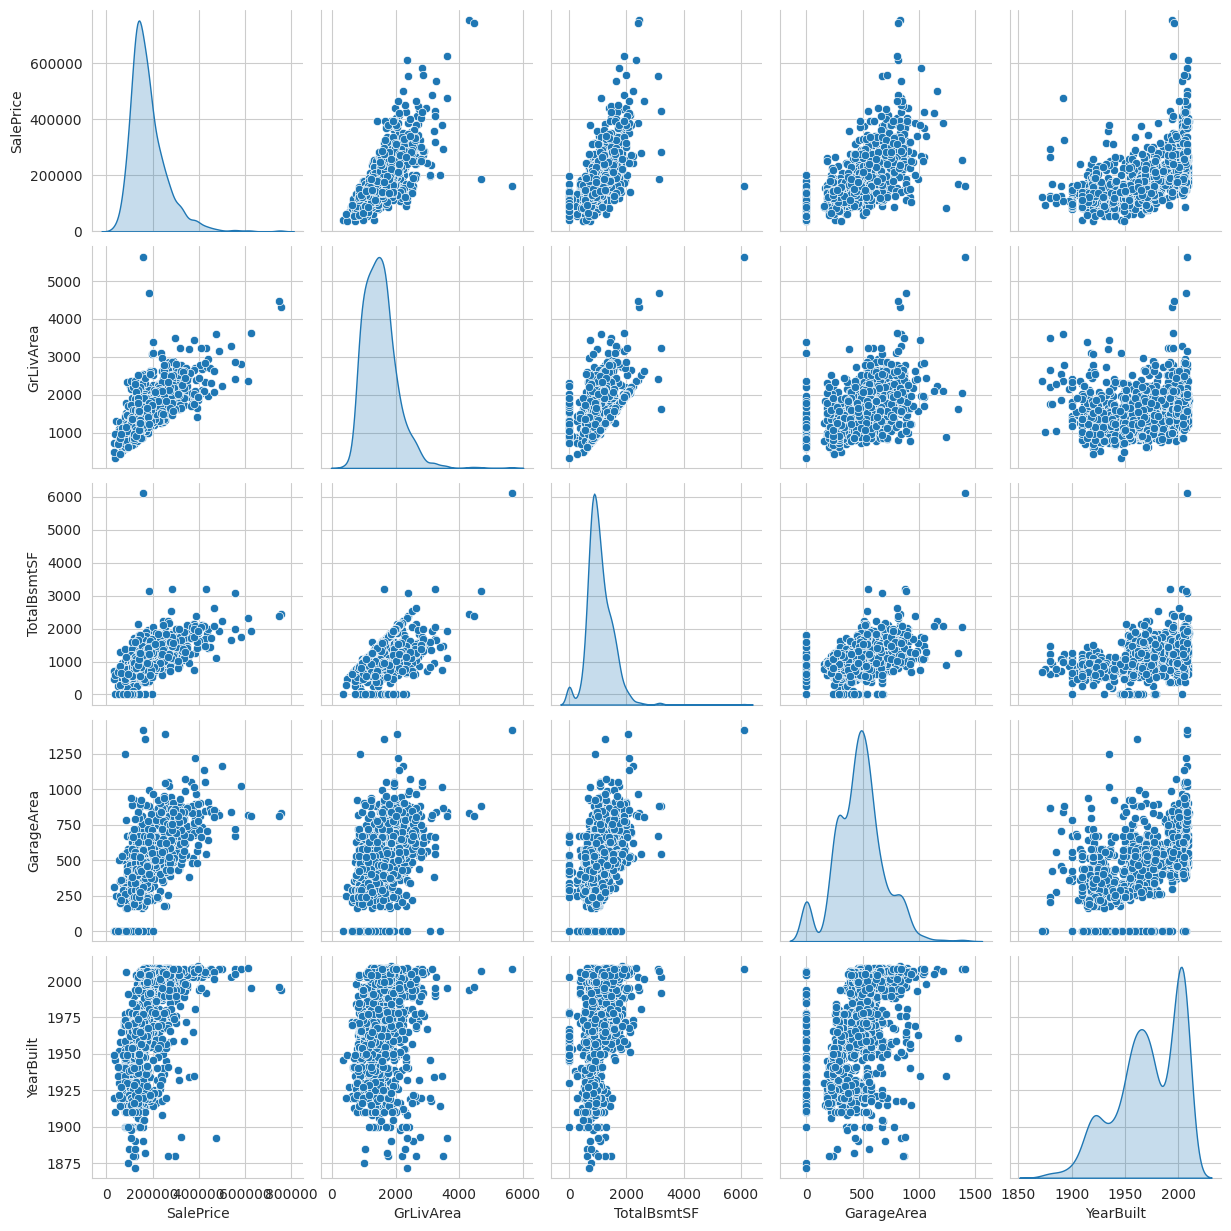

In [ ]:
selected = [
    'SalePrice',
    'GrLivArea',
    'TotalBsmtSF',
    'GarageArea',
    'YearBuilt'
]

sns.pairplot(df[selected], diag_kind='kde')

plt.show()

In [ ]:
Q1 = df['GrLivArea'].quantile(0.25)
Q3 = df['GrLivArea'].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

grlivarea_outliers = df[
    (df['GrLivArea'] < lower_limit) |
    (df['GrLivArea'] > upper_limit)
]

print("GrLivArea IQR Outliers:", len(grlivarea_outliers))

GrLivArea IQR Outliers: 31


In [ ]:


z_scores_grlivarea = stats.zscore(df['GrLivArea'])

grlivarea_z_outliers = df[abs(z_scores_grlivarea) > 3]

print("GrLivArea Z-score Outliers:", len(grlivarea_z_outliers))

GrLivArea Z-score Outliers: 16


In [ ]:
common_outliers = grlivarea_outliers.index.intersection(
    grlivarea_z_outliers.index
)

print("Common outliers:", len(common_outliers))

Common outliers: 16


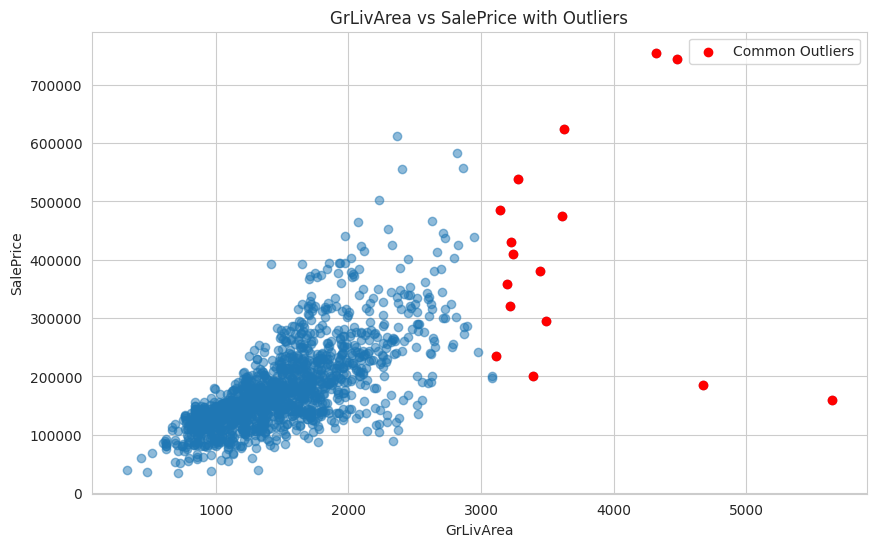

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(df['GrLivArea'], df['SalePrice'], alpha=0.5)

plt.scatter(
    df.loc[common_outliers, 'GrLivArea'],
    df.loc[common_outliers, 'SalePrice'],
    color='red',
    label='Common Outliers'
)

plt.xlabel('GrLivArea')
plt.ylabel('SalePrice')
plt.title('GrLivArea vs SalePrice with Outliers')
plt.legend()
plt.show()

In [ ]:
invalid_years = df[df['YearBuilt'] > df['YrSold']]

print("Invalid Year Records:", len(invalid_years))

Invalid Year Records: 0


In [ ]:
area_columns = ['GrLivArea', 'LotArea', 'TotalBsmtSF', 'GarageArea']

for col in area_columns:
    print(col, "Negative values:", (df[col] < 0).sum())

GrLivArea Negative values: 0
LotArea Negative values: 0
TotalBsmtSF Negative values: 0
GarageArea Negative values: 0


In [ ]:
for col in df.select_dtypes(include='object').columns:
    print(col, ":", df[col].nunique())

MSZoning : 5
Street : 2
Alley : 2
LotShape : 4
LandContour : 4
Utilities : 2
LotConfig : 5
LandSlope : 3
Neighborhood : 25
Condition1 : 9
Condition2 : 8
BldgType : 5
HouseStyle : 8
RoofStyle : 6
RoofMatl : 8
Exterior1st : 15
Exterior2nd : 16
MasVnrType : 3
ExterCond : 5
Foundation : 6
BsmtQual : 4
BsmtCond : 4
BsmtExposure : 4
BsmtFinType1 : 6
BsmtFinType2 : 6
Heating : 6
HeatingQC : 5
CentralAir : 2
Electrical : 5
Functional : 7
FireplaceQu : 5
GarageType : 6
GarageFinish : 3
GarageQual : 5
GarageCond : 5
PavedDrive : 3
PoolQC : 3
Fence : 4
MiscFeature : 4
SaleType : 9
SaleCondition : 6


In [ ]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0].sort_values(ascending=False))

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [ ]:
df_clean = df.copy()

# Fill missing values where NA means the feature is absent
none_columns = [
    'PoolQC', 'MiscFeature', 'Alley', 'Fence',
    'FireplaceQu', 'GarageType', 'GarageFinish',
    'GarageQual', 'GarageCond',
    'BsmtExposure', 'BsmtFinType2', 'BsmtQual',
    'BsmtCond', 'BsmtFinType1', 'MasVnrType'
]

for col in none_columns:
    df_clean[col] = df_clean[col].fillna('None')

print("Missing values handled for absent features.")

Missing values handled for absent features.


In [ ]:
df_clean['LotFrontage'] = df_clean['LotFrontage'].fillna(
    df_clean['LotFrontage'].median()
)

df_clean['MasVnrArea'] = df_clean['MasVnrArea'].fillna(
    df_clean['MasVnrArea'].median()
)

df_clean['GarageYrBlt'] = df_clean['GarageYrBlt'].fillna(
    df_clean['GarageYrBlt'].median()
)

print("Numerical missing values handled.")

Numerical missing values handled.


In [ ]:
df_clean['Electrical'] = df_clean['Electrical'].fillna(
    df_clean['Electrical'].mode()[0]
)

print("Electrical missing value handled.")

Electrical missing value handled.


In [ ]:
print("Remaining missing values:", df_clean.isnull().sum().sum())

Remaining missing values: 0


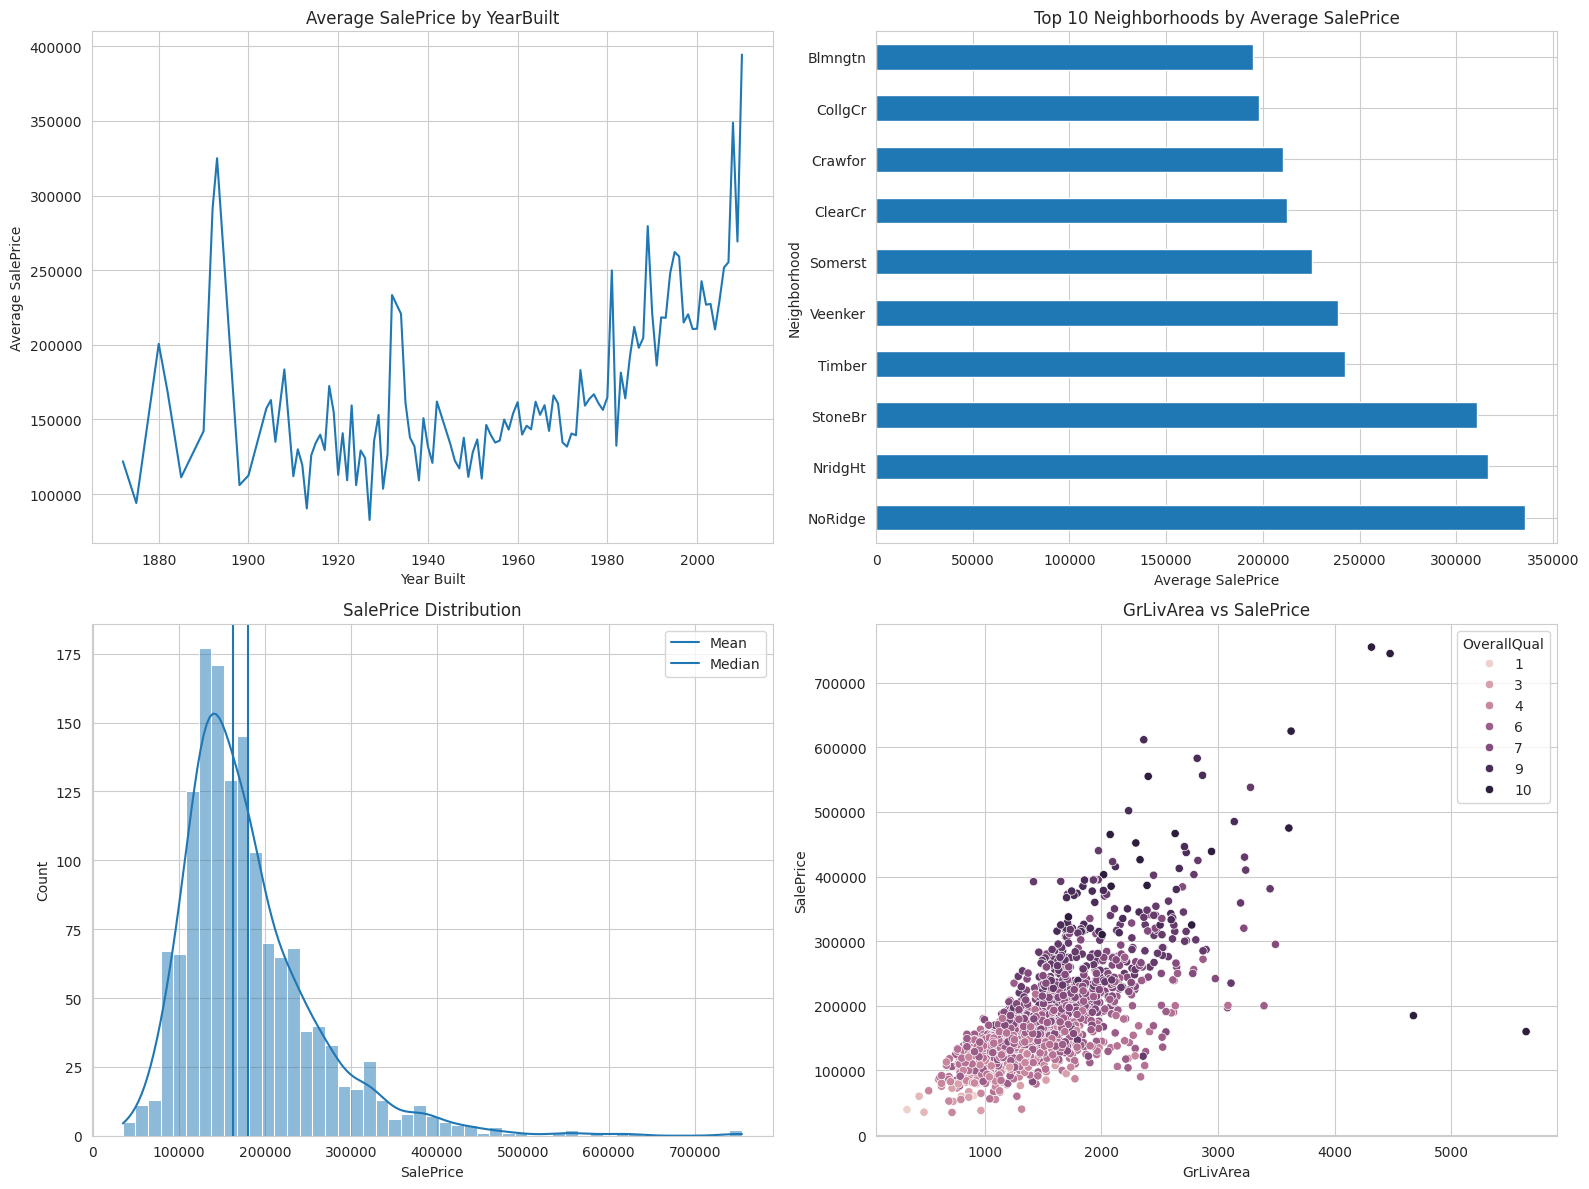

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Average SalePrice by YearBuilt
year_price = df_clean.groupby('YearBuilt')['SalePrice'].mean()
axes[0, 0].plot(year_price.index, year_price.values)
axes[0, 0].set_title('Average SalePrice by YearBuilt')
axes[0, 0].set_xlabel('Year Built')
axes[0, 0].set_ylabel('Average SalePrice')

# 2. Top 10 Neighborhoods by Average SalePrice
neighborhood_price = df_clean.groupby('Neighborhood')['SalePrice'].mean().nlargest(10)
neighborhood_price.plot(kind='barh', ax=axes[0, 1])
axes[0, 1].set_title('Top 10 Neighborhoods by Average SalePrice')
axes[0, 1].set_xlabel('Average SalePrice')

# 3. SalePrice Distribution
sns.histplot(df_clean['SalePrice'], kde=True, ax=axes[1, 0])
axes[1, 0].axvline(df_clean['SalePrice'].mean(), label='Mean')
axes[1, 0].axvline(df_clean['SalePrice'].median(), label='Median')
axes[1, 0].set_title('SalePrice Distribution')
axes[1, 0].legend()

# 4. GrLivArea vs SalePrice
sns.scatterplot(data=df_clean, x='GrLivArea', y='SalePrice',
                hue='OverallQual', ax=axes[1, 1])
axes[1, 1].set_title('GrLivArea vs SalePrice')

plt.tight_layout()
plt.savefig('eda_dashboard.png', dpi=300)
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
import zipfile

zip_path = '/content/house-prices-advanced-regression-techniques.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/house_data')

print("Files extracted successfully!")

In [ ]:
import os

print(os.listdir('/content/house_data'))

In [ ]:
import pandas as pd

# Load training dataset
df = pd.read_csv('/content/house_data/train.csv')

# Display first 5 rows
df.head()

In [ ]:


# Check dataset information
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display data types and non-null values
print("\nDataset Information:")
df.info()


## Step 3: Descriptive Statistics

Descriptive statistics help us understand the numerical data.
We calculate count, mean, standard deviation, minimum,
maximum and other statistical values.

In [ ]:
# Display descriptive statistics
df.describe()

### Observation

1. The table shows statistical information about numerical columns.
2. Mean represents the average value of each column.
3. Standard deviation shows how much values vary.
4. Minimum and maximum show the lowest and highest values.
5. These statistics help us understand the dataset.

In [ ]:

# Check missing values in each column

missing_values = df.isnull().sum()

# Display columns having missing values
missing_values = missing_values[missing_values > 0]

# Sort values in descending order
missing_values = missing_values.sort_values(ascending=False)

display(missing_values)


In [ ]:

# Calculate missing value percentage

missing_percent = (df.isnull().sum() / len(df)) * 100

# Display columns with missing values
missing_percent = missing_percent[missing_percent > 0]

# Sort in descending order
missing_percent = missing_percent.sort_values(ascending=False)

display(missing_percent)


In [ ]:

# Statistical summary of numerical columns

df.describe()


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Plot house price distribution

plt.figure(figsize=(8, 5))
sns.histplot(df['SalePrice'], kde=True)

plt.title('Distribution of House Prices')
plt.xlabel('House Price')
plt.ylabel('Frequency')

plt.show()


In [ ]:

# Calculate correlation between numerical columns

correlation = df.corr(numeric_only=True)

# Display correlation with SalePrice
price_corr = correlation['SalePrice'].sort_values(ascending=False)

display(price_corr)


In [ ]:


# Create correlation heatmap

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    cmap='coolwarm',
    annot=False
)

plt.title('Correlation Heatmap')
plt.show()


In [ ]:

# Find top 10 features correlated with SalePrice

top_features = price_corr.drop('SalePrice').head(10)

display(top_features)


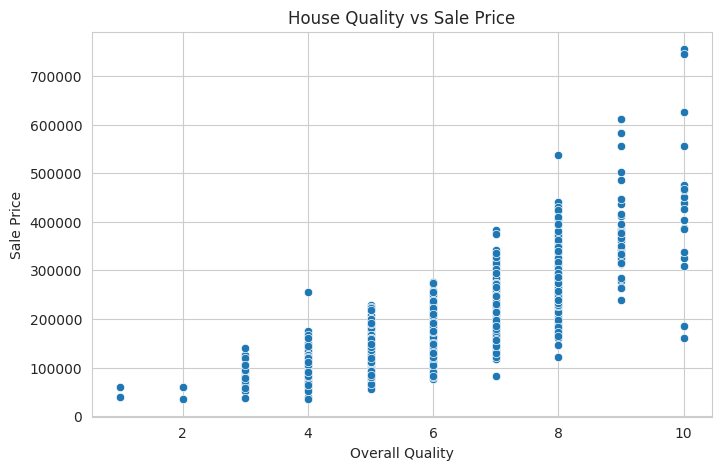

In [ ]:

# Relationship between house quality and price

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x='OverallQual',
    y='SalePrice',
    data=df
)

plt.title('House Quality vs Sale Price')
plt.xlabel('Overall Quality')
plt.ylabel('Sale Price')

plt.show()


In [ ]:

# Detect outliers using IQR method

Q1 = df['SalePrice'].quantile(0.25)
Q3 = df['SalePrice'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['SalePrice'] < lower_limit) |
    (df['SalePrice'] > upper_limit)
]

print("Number of outliers:", len(outliers))
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)


Number of outliers: 61
Lower limit: 3937.5
Upper limit: 340037.5


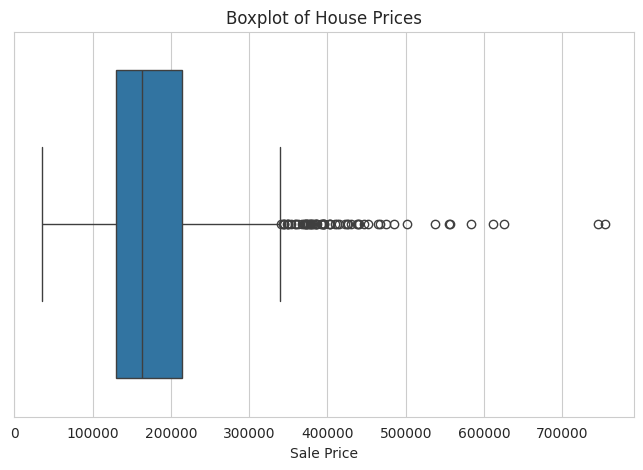

In [ ]:

plt.figure(figsize=(8, 5))

sns.boxplot(x=df['SalePrice'])

plt.title('Boxplot of House Prices')
plt.xlabel('Sale Price')

plt.show()


In [ ]:
from scipy import stats

z_scores = stats.zscore(df['SalePrice'])
z_outliers = df[abs(z_scores) > 3]

print("Number of Z-score outliers:", len(z_outliers))

Number of Z-score outliers: 22


In [ ]:
print("IQR Outliers:", len(outliers))
print("Z-score Outliers:", len(z_outliers))

IQR Outliers: 61
Z-score Outliers: 22


In [ ]:
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

In [ ]:
missing_values = df.isnull().sum()

print("Total missing values:", missing_values.sum())
print("Columns with missing values:", (missing_values > 0).sum())

Total missing values: 7829
Columns with missing values: 19


In [ ]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [ ]:
print("Neighborhood categories:")
print(df['Neighborhood'].value_counts())

print("\nHouse Style categories:")
print(df['HouseStyle'].value_counts())

Neighborhood categories:
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64

House Style categories:
HouseStyle
1Story    726
2Story    445
1.5Fin    154
SLvl       65
SFoyer     37
1.5Unf     14
2.5Unf     11
2.5Fin      8
Name: count, dtype: int64


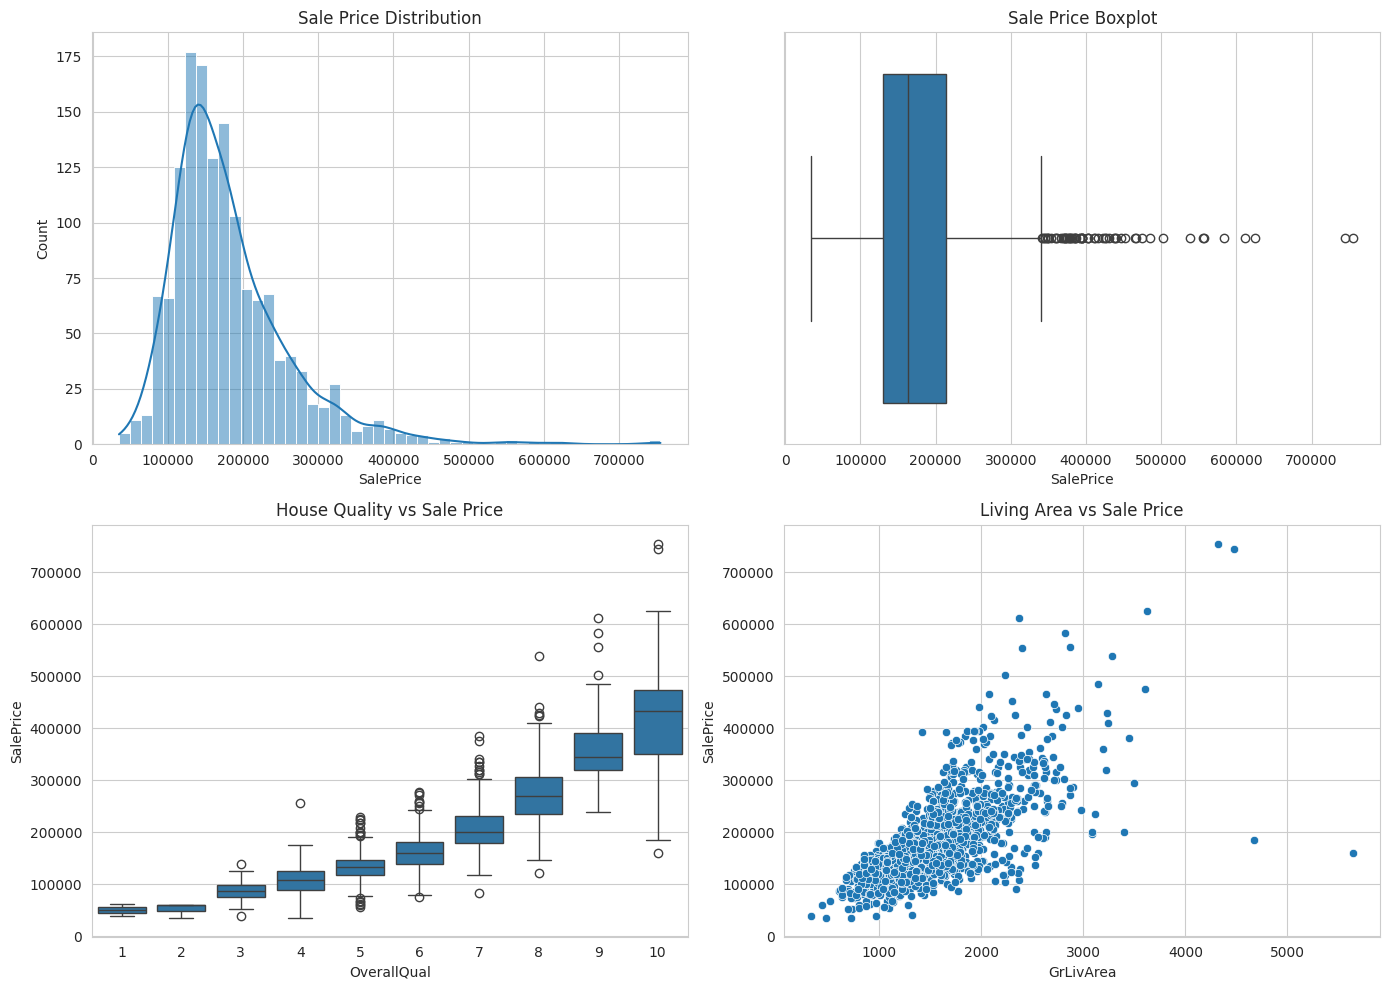

In [ ]:
plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
sns.histplot(df['SalePrice'], kde=True)
plt.title('Sale Price Distribution')

plt.subplot(2, 2, 2)
sns.boxplot(x=df['SalePrice'])
plt.title('Sale Price Boxplot')

plt.subplot(2, 2, 3)
sns.boxplot(x=df['OverallQual'], y=df['SalePrice'])
plt.title('House Quality vs Sale Price')

plt.subplot(2, 2, 4)
sns.scatterplot(x=df['GrLivArea'], y=df['SalePrice'])
plt.title('Living Area vs Sale Price')

plt.tight_layout()
plt.show()

## Conclusion

In this project, I performed Exploratory Data Analysis (EDA) on the House Prices dataset containing 1,460 rows and 81 columns.

- Analyzed numerical and categorical data.
- Studied missing values and duplicate records.
- Used histograms, boxplots, scatterplots and a correlation heatmap.
- Identified outliers using IQR and Z-score methods.
- Observed the relationship between house quality, living area and sale price.
- Created a final dashboard to summarize the analysis.

**Overall, this project helped me understand the dataset, identify patterns and discover factors related to house prices using Python libraries.**

In [ ]:

import zipfile
import glob
import os

# Find the uploaded ZIP file
zip_file = glob.glob('/content/house-prices*.zip')[0]

# Extract the ZIP file
with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/house_data')

# Display extracted files
print(os.listdir('/content/house_data'))


In [ ]:

import os

# Display files uploaded in Colab
print(os.listdir('/content'))


In [ ]:



import os

# Check files in the main directory
print(os.listdir('/'))


In [ ]:

from google.colab import files

uploaded = files.upload()


In [ ]:

import zipfile
import os

# Extract the downloaded ZIP file
with zipfile.ZipFile('house-prices-advanced-regression-techniques.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/house_data')

# Display extracted files
print(os.listdir('/content/house_data'))


In [ ]:
# Exploratory Data Analysis of House Prices

## Step 1: Setup and First Look

In this step, we will import the required Python libraries, load the house prices dataset and examine its structure, columns and missing values.

In [ ]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set plotting style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully!")


In [ ]:

# Load the dataset

df = pd.read_csv('/content/house_data/train.csv')

# Display dataset shape
print("Dataset Shape:", df.shape)

# Display first 5 rows
display(df.head())

# Display information about dataset
df.info()


In [ ]:

# Count missing values in each column

missing = df.isnull().sum()

# Calculate missing value percentage
missing_percentage = (missing / len(df)) * 100

# Create missing values table
missing_data = pd.DataFrame({
    'Missing Values': missing,
    'Percentage': missing_percentage
})

# Sort in descending order
missing_data = missing_data.sort_values(
    by='Missing Values',
    ascending=False
)

# Display columns having missing values
display(missing_data[missing_data['Missing Values'] > 0])


## Step 1: Observation

1. The dataset contains 1460 rows and 81 columns.
2. Each row represents information about one house.
3. The dataset contains numerical and categorical features.
4. Some columns contain missing values.
5. The dataset is suitable for further exploratory data analysis.



## Step 2: Classify Variables

In this step, we will classify the dataset columns into numerical, categorical and ordinal variables.


In [ ]:

# Identify numerical and categorical columns

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

categorical_cols = df.select_dtypes(include='object').columns.tolist()

print("Numerical Columns:", len(numeric_cols))
print("Categorical Columns:", len(categorical_cols))

print("\nNumerical Column Names:")
print(numeric_cols)

print("\nCategorical Column Names:")
print(categorical_cols)


In [ ]:

# Define ordinal columns

ordinal_cols = ['OverallQual', 'ExterQual', 'KitchenQual']

print("Ordinal Columns:")
print(ordinal_cols)


In [ ]:

# Create variable summary

summary = pd.DataFrame({
    'Column Name': df.columns,
    'Data Type': df.dtypes.values,
    'Unique Values': df.nunique().values
})

display(summary)


## Step 2: Observation

1. The dataset contains numerical and categorical variables.
2. Numerical variables represent values such as price, area and year.
3. Categorical variables represent groups such as neighborhood and house style.
4. Ordinal variables represent ordered categories such as house quality.
5. OverallQual is stored as a number but represents an ordered quality level.